# 01 – Data Exploration & Preprocessing

## 1. Project Setup

In [60]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Resolve the repository root whether Jupyter starts here or in notebooks/.
repo_root = Path.cwd()
if not (repo_root / "src").is_dir():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.python import data_loader, data_validation, preprocessing


## 2. Data Loading

In [61]:
raw_data_path = repo_root / "data" / "raw" / "TGSIM_I294_L2_Trajectories.csv"
df = data_loader.load_data(raw_data_path)


## 3. Initial Data Inspection

In [62]:
df.head()

,id,time,xloc_kf,yloc_kf,lane_kf,speed_kf,acceleration_kf,length_smoothed,width_smoothed,type_most_common,acc,run_index
0,143,38.1,"1,778.595",135.24,-5,23.15,0.0,5.45,2.67,small-vehicle,no,5
1,143,38.2,"1,780.91",135.60,-5,23.15,-0.5,5.45,2.67,small-vehicle,no,5
2,143,38.3,"1,783.225",135.97,-5,23.10,1.0,5.45,2.67,small-vehicle,no,5
3,143,38.4,"1,785.535",136.33,-5,23.20,-1.0,5.45,2.67,small-vehicle,no,5
4,143,38.5,"1,787.855",136.70,-5,23.10,1.0,5.45,2.67,small-vehicle,no,5


In [63]:
data_validation.get_dataset_info(df)

{'rows': 137928, 'columns': 12, 'unique_vehicles': 404, 'unique_runs': 12}

## 4. Data Quality Assessment

In [64]:
data_validation.check_data_quality(df)

{'missing_values': id                  0
 time                0
 xloc_kf             0
 yloc_kf             0
 lane_kf             0
 speed_kf            0
 acceleration_kf     0
 length_smoothed     0
 width_smoothed      0
 type_most_common    0
 acc                 0
 run_index           0
 dtype: int64,
 'duplicates': np.int64(0)}

In [65]:
data_validation.check_data_types(df)

id                    int64
time                float64
xloc_kf                 str
yloc_kf             float64
lane_kf               int64
speed_kf            float64
acceleration_kf     float64
length_smoothed     float64
width_smoothed      float64
type_most_common        str
acc                     str
run_index             int64
dtype: object

In [66]:
df['xloc_kf']

0         1,778.595
1          1,780.91
2         1,783.225
3         1,785.535
4         1,787.855
            ...    
137923     1,512.56
137924     1,515.04
137925    1,517.525
137926    1,520.005
137927    1,522.495
Name: xloc_kf, Length: 137928, dtype: str

## 5. Descriptive Statistics

In [67]:
df.describe()

,id,time,yloc_kf,lane_kf,speed_kf,acceleration_kf,length_smoothed,width_smoothed,run_index
count,137928.000000,137928.000000,137928.000000,137928.000000,137928.000000,137928.000000,137928.000000,137928.000000,137928.000000
mean,222.587038,30.973523,166.891595,-0.713140,27.413271,0.041181,7.971611,2.726912,30.923475
std,143.868103,12.909065,35.165366,3.581946,3.757788,1.555288,4.885210,0.124668,10.376785
min,0.000000,5.000000,92.700000,-5.000000,14.750000,-22.000000,4.940000,2.670000,5.000000
25%,98.000000,21.200000,140.690000,-4.000000,24.750000,-0.500000,5.770000,2.670000,29.000000
50%,206.000000,30.900000,163.320000,-2.000000,27.400000,0.000000,6.000000,2.670000,33.000000
75%,311.000000,40.700000,190.130000,3.000000,30.200000,0.500000,6.000000,2.670000,38.000000
max,673.000000,58.900000,261.630000,5.000000,41.350000,20.000000,20.000000,3.000000,42.000000


## 6. Categorical Data Analysis

In [68]:
df["type_most_common"].value_counts()

type_most_common
small-vehicle    114141
large-vehicle     23787
Name: count, dtype: int64

In [69]:
df["acc"].value_counts()

acc
no     133809
yes      4119
Name: count, dtype: int64

In [70]:
df["lane_kf"].value_counts().sort_index()

lane_kf
-5    21389
-4    20022
-3    20181
-2    20576
 2    15860
 3    13766
 4    13322
 5    12812
Name: count, dtype: int64

## 7. Data Visualization

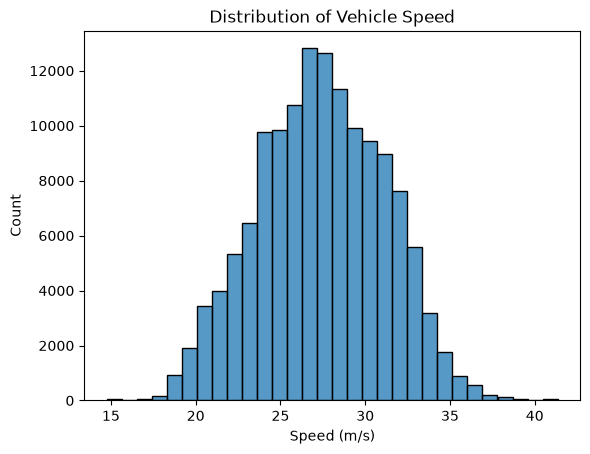

In [71]:
sns.histplot(data=df, x="speed_kf", bins=30)
plt.title("Distribution of Vehicle Speed")
plt.xlabel("Speed (m/s)")
plt.show()

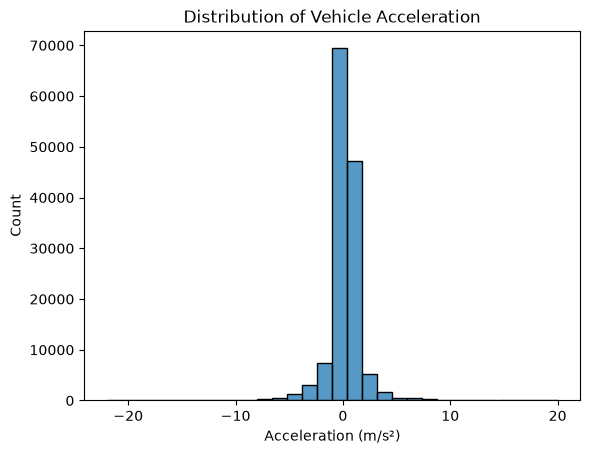

In [72]:
sns.histplot(data=df, x="acceleration_kf", bins=30)
plt.title("Distribution of Vehicle Acceleration")
plt.xlabel("Acceleration (m/s²)")
plt.show()

## 9. Data Preprocessing

In [73]:
df_processed = preprocessing.preprocess_data(df)

processed_data_path = repo_root / "data" / "processed" / "cleaned_trajectories.csv"
processed_data_path.parent.mkdir(parents=True, exist_ok=True)
df_processed.to_csv(processed_data_path, index=False)
print(f"Saved {len(df_processed):,} rows to {processed_data_path}")


Saved 137,928 rows to c:\Users\nasty\Desktop\PetProjects\vehicle-trajectory-analytics\data\processed\cleaned_trajectories.csv


## 10. Processed Data Validation

In [74]:
# Confirm the preprocessing produced numeric coordinates and chronological rows.
assert pd.api.types.is_numeric_dtype(df_processed["xloc_kf"])
assert not df_processed[["run_index", "id", "time"]].isna().any().any()

df_processed[["run_index", "id", "time", "xloc_kf", "speed_kf", "acceleration_kf"]].head()


,run_index,id,time,xloc_kf,speed_kf,acceleration_kf
0,5,143,38.1,1778.595,23.15,0.0
1,5,143,38.2,1780.910,23.15,-0.5
2,5,143,38.3,1783.225,23.10,1.0
3,5,143,38.4,1785.535,23.20,-1.0
4,5,143,38.5,1787.855,23.10,1.0


## 11. Initial data exploration findings

- The file contains **137,928 observations**, **404 vehicle IDs**, and **12 runs**.
- The initial quality checks report **no missing values** and **no fully duplicated rows**.
- `xloc_kf` is read as text because its values contain thousands separators (for example, `1,778.595`). Preprocessing removes those separators and converts the coordinate to numeric before sorting.
- The dataset contains **114,141 small vehicles** and **23,787 large vehicles**. ACC labels are imbalanced: **4,119 “yes”** and **133,809 “no”** observations.
- The recorded mean speed is about **27.4 m/s (98.7 km/h)**. Acceleration has a small positive mean, while the distribution includes substantial positive and negative values that should be inspected before event thresholds are chosen.

These are descriptive results from the current file. Rows are repeated measurements from vehicles, so observation counts should not be treated as independent vehicle counts. The following sections compare groups and identify records for further inspection; they do not establish causes or safety outcomes.
